# The Pacific warms. How does the Atlantic respond?
## ENSO, North Atlantic storm activity, and the geography of storm tracks

**ENSO Storm Atlas · Research notebook**

Historical archive: 1950–2025 · Primary analysis: 1966–2025 · Executed analysis and figures

A seasonal count tells us how active the Atlantic was. A map tells us where that activity occurred. This notebook connects the two: **How much activity changes; which track types account for the difference; how their composition and locations move the population centroid; and how much information remains in an individual track.**

Tables, quantitative result statements, and seven figure sets are generated from a versioned snapshot. Each figure is exported as a 300 dpi PNG and PDF/SVG vector artwork. To reproduce the analysis, install `requirements-notebook.txt` and run `python scripts/run_research_notebook.py` from the repository root.

## 1. Background and research questions

El Niño–Southern Oscillation (ENSO) links tropical Pacific sea-surface temperature anomalies to atmospheric circulation. NOAA identifies stronger Atlantic vertical wind shear as one pathway through which El Niño can inhibit tropical cyclone formation and development [1]. Historical records allow us to examine the associated seasonal differences in activity and geography.

A geographic shift need not imply that every storm changes course. If western Gulf–Caribbean tracks become less common, the population's average position can move east even when each type's location is unchanged. Conversely, northward displacement within existing types can move the population centroid without a large change in their shares. **Composition and within-type location therefore need to be separated.**

Mass moments provide compact summaries of track location and spread. Nakamura et al. used such moments to classify North Atlantic tropical cyclone tracks [2]. Here, centroid coordinates, variances, and covariance describe each track; skewness and excess kurtosis describe its spatial distribution. Track types are defined separately using resampled trajectories.

| Question | Estimand | Evidence |
|---|---|---|
| Q1. How does seasonal activity differ? | La Niña minus El Niño mean storm count, ACE, and US-landfall storm count | Figs. 1–2; seasonal contrasts |
| Q2. Which types account for the count difference? | Type counts per season; pooled storm shares reported separately | Fig. 3; four rate contrasts |
| Q3. What accounts for centroid displacement? | El Niño minus La Niña centroid; composition and within-type components | Fig. 4; exact decomposition |
| Q4. Which findings persist across settings? | Geometry and K, detrending, count windows, single-season influence, temporal alignment | Fig. 5 and sensitivity tables |
| Q5. How informative is one track? | Season-grouped AUC and the paired higher-order increment | Figs. 6–7; permutations and bootstrap |

This observational study examines historical associations. The questions organize an exploratory analysis, not a preregistered testing plan. The season is the exposure and resampling unit; storms are the observations used to describe track geography.

## 2. Data, definitions, and inferential design

Records originate from NOAA NCEI IBTrACS v04r01 [3] and NOAA CPC ONI [4]. The bundled snapshot is the processed input used by the atlas. `data/manifest.json` records source URLs, the source-code commit, and SHA-256 checksums. Natural Earth / world-atlas supplies map backgrounds [5].

| Quantity | Definition |
|---|---|
| ENSO exposure | August–October (ASO) ONI: El Niño ≥ +0.5°C, La Niña ≤ −0.5°C, otherwise neutral. A seasonal grouping rule, not the five-consecutive-season event definition. |
| Eligible storm | A 1950–2025 `main` or `PROVISIONAL` system with at least one tropical/subtropical fix at `USA_WIND` ≥34 kt. Includes tropical storms and hurricanes. |
| Track | Synoptic 00, 06, 12, and 18 UTC fixes from the first eligible fix to the endpoint, including subsequent extratropical positions. Missing-coordinate fixes were removed during preprocessing. Snapshot coordinates have 0.1° precision. |
| ACE | $10^{-4}\sum_t v_t^2$ for tropical/subtropical fixes with winds ≥34 kt; seasonal totals sum per-storm values. |
| US-landfall storm count | Distinct storms with a `LANDFALL=0`, wind ≥34 kt fix within the selected contiguous-US polygon tolerance of 0.05°. Multiple fixes count once; this operational indicator is not an event count. |
| Track centroid | Arithmetic mean longitude and latitude of retained fixes. Storms have equal weight in pooled centroid contrasts. |
| Type share | Type count divided by all storms in the same phase; distinct from the mean count per season. |
| AUC | Area under the ROC curve: ranking discrimination, not classification accuracy. |

The **1966–2025** primary window reduces reliance on the earliest observing period while retaining a substantial record. Count sensitivity analyses also start in 1950 and 1980; the windows do not by themselves establish archive homogeneity.

Raw preprocessing is in `scripts/download_data.py` and `scripts/build_data.py`. This notebook starts from the checksum-verified processed snapshot and recomputes statistical results without reading the website's fitted AUC or decomposition outputs.

In [1]:
import os
for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[variable] = '1'
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
%matplotlib inline
HERE = Path.cwd()
NOTEBOOK_DIR = HERE if (HERE / 'atlas_analysis.py').exists() else HERE / 'notebooks'
sys.path.insert(0, str(NOTEBOOK_DIR))
import atlas_analysis as aa

d, years, storms, tracks, features, season, cohorts = aa.load_data()
display(cohorts)
display(Markdown(f"**Verified input:** {len(storms)} unique storms across {len(years)} seasons; "
                 f"{int((storms.y >= 1966).sum())} storms in the primary window. "
                 "The primary comparison contains **226 La Niña storms in 14 seasons** and "
                 "**165 El Niño storms in 15 seasons**; 31 neutral seasons contain 399 storms. "
                 "All 391 non-neutral storms have finite nine-moment summaries. Four neutral storms "
                 "lack four fixes and are excluded only from nine-moment analyses. "
                 "Packed winds reproduce ACE within the per-storm rounding tolerance."))

,start,phase,seasons,storms,finite_nine_moments
0,1950,nina,18,284,284
1,1950,neutral,38,476,472
2,1950,nino,20,219,219
3,1966,nina,14,226,226
4,1966,neutral,31,399,395
5,1966,nino,15,165,165
6,1980,nina,10,175,175
7,1980,neutral,24,324,320
8,1980,nino,12,127,127


**Verified input:** 979 unique storms across 76 seasons; 790 storms in the primary window. The primary comparison contains **226 La Niña storms in 14 seasons** and **165 El Niño storms in 15 seasons**; 31 neutral seasons contain 399 storms. All 391 non-neutral storms have finite nine-moment summaries. Four neutral storms lack four fixes and are excluded only from nine-moment analyses. Packed winds reproduce ACE within the per-storm rounding tolerance.

### Inference and uncertainty

Storms in one season share an ENSO exposure. Primary tests exchange **whole-season phase labels**, preserving every storm within its year. Bootstrap samples draw whole seasons with replacement within each phase. Seasonal means weight years equally; pooled centroid and moment contrasts weight storms equally while still resampling years.

- **Activity and type rates:** 9,999 two-sided permutations and 5,000 season bootstraps; Holm correction separately for three activity outcomes and four type-rate contrasts.
- **Primary decomposition:** 3,999 two-sided permutations and 2,000 season bootstraps; Holm correction across six components (total, type mix, within type for each coordinate).
- **Moment contrasts:** 9,999 two-sided permutations; Benjamini–Hochberg (BH) adjustment across nine moments.
- **Classification:** ten repetitions of ten-fold year-grouped validation; 199 season-label permutations, with BH adjustment across six feature sets; 1,000 paired season bootstraps for the higher-order increment.

Monte Carlo p values are $(b+1)/(B+1)$, counting null statistics at least as extreme as observed. Two-sided tests use absolute contrasts; AUC uses a one-sided upper-tail test. Percentile bootstrap 95% intervals have marginal, not simultaneous, coverage. Correction is within stated families, not across the notebook.

Decomposition permutations assess the **global null of no phase association**, using each component as a statistic. They are not conditional tests of one zero component while other components remain nonzero. Component intervals condition on the chosen labels; clusters are not refitted within bootstraps.

Whole-year resampling accounts for within-season dependence but assumes exchangeability across years. Section 6 also rotates the full ENSO sequence relative to the storm record, preserving cyclic serial structure. That sensitivity has a different stationarity assumption and a coarser reference distribution.

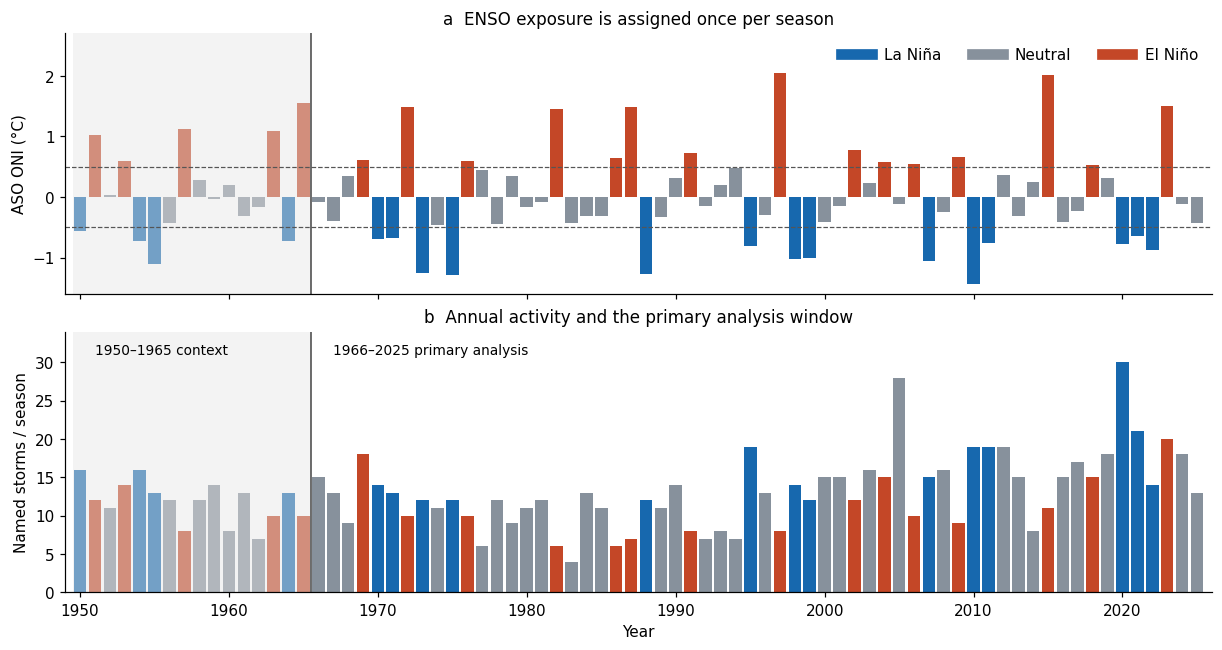

In [2]:
aa.fig_context(season)

**Figure 1 | ENSO exposure and the seasonal record.** ASO ONI (a) and counts (b) for 76 seasons, 1950–2025. Blue, grey, and orange denote La Niña, neutral, and El Niño. Shading marks the 1950–1965 context period; primary analysis uses 60 seasons from 1966 onward. Dashed ONI lines mark ±0.5°C thresholds.

The record establishes the scale of variability before phase averages are compared. We next ask whether count differences accompany changes in accumulated intensity and US-landfall storm counts.

## 3. Activity: counts, accumulated intensity, and US-landfall storms

For each seasonal outcome $Y$,

$$\Delta_{\mathrm{activity}}=\overline{Y}_{\mathrm{La\ Niña}}-\overline{Y}_{\mathrm{El\ Niño}}.$$

Positive values indicate greater La Niña activity. Neutral seasons provide context but are not part of the primary tests. ACE measures accumulated wind intensity; the US indicator counts distinct qualifying storms near the contiguous-US coastline.

,outcome,nina_mean,nino_mean,delta_nina_minus_nino,ci_low,ci_high,p_permutation,p_holm
0,storms,16.1429,11.0000,5.1429,2.0142,8.5051,0.0055,0.0165
1,ace,128.6729,80.7707,47.9022,8.5846,85.2546,0.0267,0.0267
2,us,4.2857,2.2667,2.0190,0.6333,3.4525,0.0086,0.0172


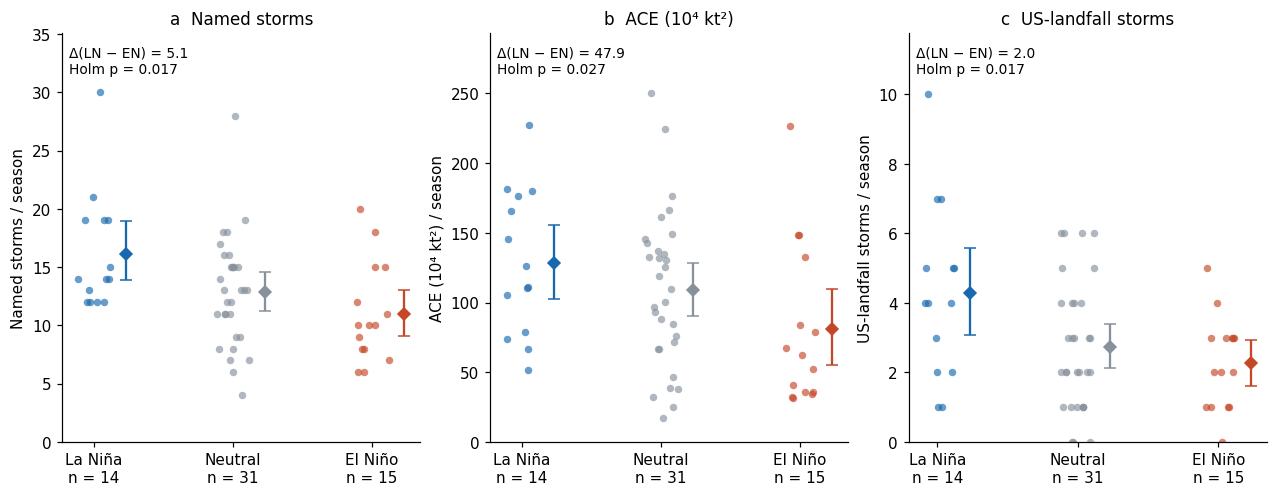

- **Storms per season:** La Niña 16.14, El Niño 11.00; difference 5.14, 95% CI [2.01, 8.51], Holm-adjusted p=0.0165.
- **Seasonal ACE:** La Niña 128.67, El Niño 80.77; difference 47.90, 95% CI [8.58, 85.25], Holm-adjusted p=0.0267.
- **US-landfall storms per season:** La Niña 4.29, El Niño 2.27; difference 2.02, 95% CI [0.63, 3.45], Holm-adjusted p=0.0172.

In [3]:
activity = aa.seasonal_results(season)
display(activity.round(4))
aa.fig_activity(season, activity)
lines = []
for _, r in activity.iterrows():
    name = {'storms': 'Storms per season', 'ace': 'Seasonal ACE', 'us': 'US-landfall storms per season'}[r.outcome]
    lines.append(f"- **{name}:** La Niña {r.nina_mean:.2f}, El Niño {r.nino_mean:.2f}; "
                 f"difference {r.delta_nina_minus_nino:.2f}, 95% CI [{r.ci_low:.2f}, {r.ci_high:.2f}], "
                 f"Holm-adjusted p={r.p_holm:.4f}.")
display(Markdown('\n'.join(lines)))

**Figure 2 | Three measures of seasonal activity.** Small points are individual seasons: n=14 La Niña, 31 neutral, 15 El Niño. Diamonds show means; error bars show 95% intervals from 5,000 within-phase season bootstraps. Labels report La Niña minus El Niño contrasts and Holm-adjusted p values from 9,999 season permutations across three outcomes. ACE is in $10^4$ kt² units; US counts refer to storms rather than events.

Activity differs at the population level. To connect that contrast to geography, we identify which types contribute to the count difference.

## 4. Composition: which tracks account for the count difference?

Primary analysis retains the atlas's four shared labels, fitted without ENSO labels to the 1950–2025 archive. One definition across phases makes type comparisons interpretable.

Notebook trajectories use **haversine great-circle distances** between adjacent fixes [6]. Longitude is unwrapped, stationary duplicate distance knots are removed, and coordinates are linearly interpolated at 16 equally spaced cumulative distances. In the 32-dimensional clustering vector, longitude is multiplied by $\cos25^\circ$. This separates along-track distance from the fixed coordinate weighting used by K-Means.

The archive labels used a coordinate-space approximation. Rather than silently redefine them, we refit **geodesic K=3–7** solutions (20 initializations; seed 0) and examine their decompositions in Section 6. Silhouette scores describe alternatives; the adjusted Rand index (ARI) measures agreement with fixed labels. Types are descriptive geographic groups, not a formal taxonomy. Cluster membership is not a classifier input.

,K,silhouette
0,3,0.3245
1,4,0.3588
2,5,0.3351
3,6,0.2787
4,7,0.2798


Geodesic K=4 versus fixed atlas labels: **ARI=0.940**.

,type,nina_mean,nino_mean,delta_nina_minus_nino,ci_low,ci_high,p_permutation,p_holm
0,Gulf & Caribbean,5.9286,2.3333,3.5952,2.1333,5.2000,0.0002,0.0008
1,East Coast recurver,4.2857,3.2000,1.0857,-0.0477,2.2668,0.1092,0.3276
2,Mid-Atlantic recurver,3.1429,2.9333,0.2095,-1.0144,1.4335,0.7553,1.0000
3,Cape Verde type,2.7857,2.5333,0.2524,-1.3955,1.7764,0.8131,1.0000


,phase,type,storms,total_storms,share
0,nina,Gulf & Caribbean,83,226,0.3673
1,nina,East Coast recurver,60,226,0.2655
2,nina,Mid-Atlantic recurver,44,226,0.1947
3,nina,Cape Verde type,39,226,0.1726
4,neutral,Gulf & Caribbean,122,399,0.3058
5,neutral,East Coast recurver,109,399,0.2732
6,neutral,Mid-Atlantic recurver,97,399,0.2431
7,neutral,Cape Verde type,71,399,0.1779
8,nino,Gulf & Caribbean,35,165,0.2121
9,nino,East Coast recurver,48,165,0.2909


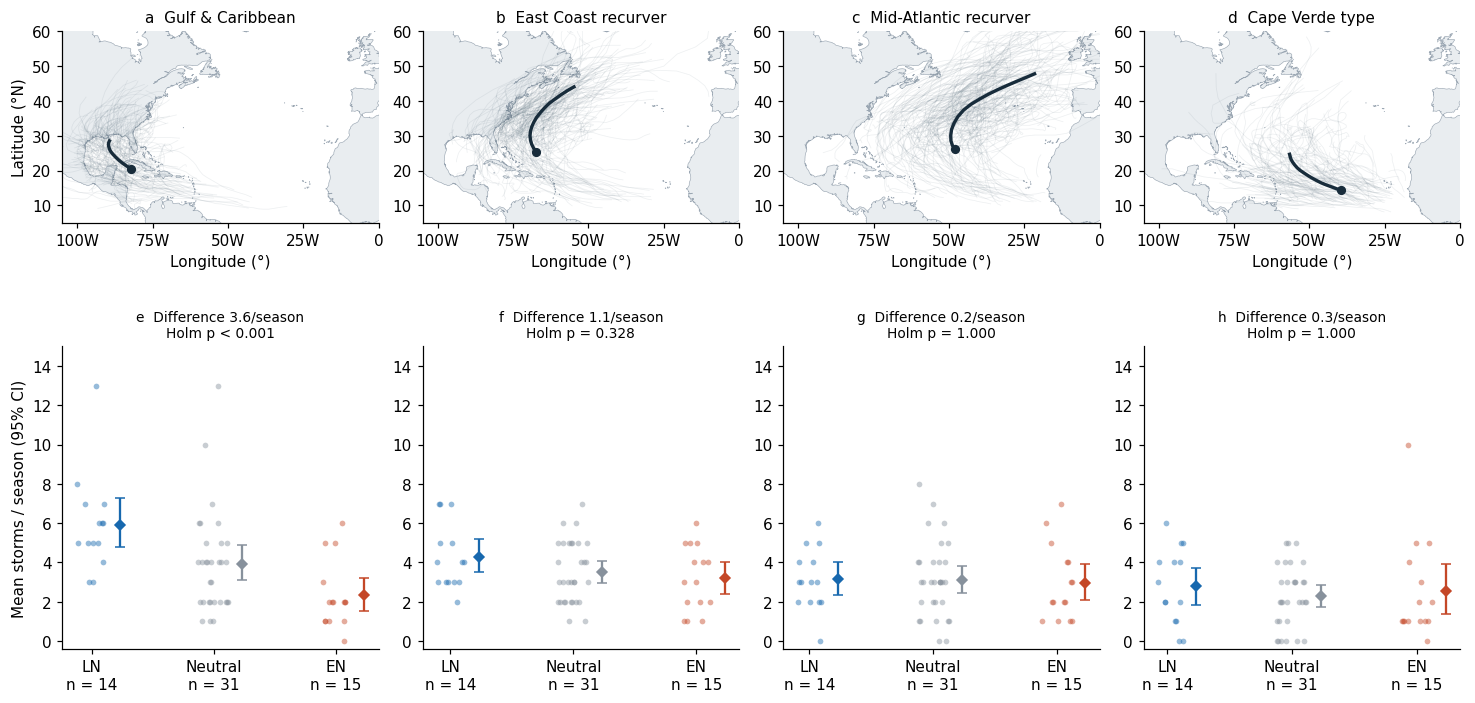

The Gulf–Caribbean type averages **5.93** La Niña versus **2.33** El Niño storms per season. Its difference of **3.60** accounts arithmetically for **69.9%** of the total count difference (Holm p=0.0008). This fraction is a descriptive contribution, not a causal attribution.

In [4]:
fits, type_rates, cluster_selection, cluster_ari = aa.cluster_results(storms, features, season)
display(cluster_selection.round(4))
display(Markdown(f"Geodesic K=4 versus fixed atlas labels: **ARI={cluster_ari:.3f}**."))
display(type_rates.round(4))
type_shares = pd.read_csv(aa.OUT / 'type_shares.csv')
display(type_shares.round(4))
aa.fig_types(storms, tracks, features, season, type_rates)
r = type_rates.iloc[0]
activity_delta = activity.loc[activity.outcome == 'storms', 'delta_nina_minus_nino'].iloc[0]
display(Markdown(f"The Gulf–Caribbean type averages **{r.nina_mean:.2f}** La Niña versus "
                 f"**{r.nino_mean:.2f}** El Niño storms per season. Its difference of **{r.delta_nina_minus_nino:.2f}** "
                 f"accounts arithmetically for **{r.delta_nina_minus_nino/activity_delta:.1%}** of the total count difference "
                 f"(Holm p={r.p_holm:.4f}). This fraction is a descriptive contribution, not a causal attribution."))

**Figure 3 | Track geography and type-specific counts.** Upper panels show 790 primary-window tracks by fixed atlas type: thin lines are individual tracks, thick lines are pointwise means of geodesically spaced positions, and dots mark mean starting positions. Lower panels show individual seasonal counts (n=14, 31, 15); diamonds and bars indicate means and 95% season-bootstrap intervals. Four La Niña minus El Niño rate comparisons use Holm-adjusted permutation p values. The map frame is 105°W–0°, 5–60°N; portions beyond the frame remain in all calculations.

**Counts and shares answer different questions.** Counts describe how many storms occur per year; pooled shares describe the storm population's composition. The next decomposition uses shares, not annual rates.

## 5. Geography: composition and within-type displacement

Let $p_k^E,p_k^L$ be the fractions of El Niño and La Niña storms in type $k$, and $\mu_k^E,\mu_k^L$ their mean centroids. Then

$$\begin{aligned}
\Delta\mu&=\sum_k p_k^E\mu_k^E-\sum_k p_k^L\mu_k^L\\
&=\underbrace{\sum_k(p_k^E-p_k^L)\frac{\mu_k^E+\mu_k^L}{2}}_{\mathrm{type\ mix}}
+\underbrace{\sum_k\frac{p_k^E+p_k^L}{2}(\mu_k^E-\mu_k^L)}_{\mathrm{within\ type}}.
\end{aligned}$$

This symmetric identity uses average weights and means. Longitude and latitude are evaluated separately; positive values mean eastward and northward El Niño displacement. The code verifies exact addition in every replicate. A missing type makes a resampled component undefined and raises an error rather than being filled with zero.

The centroid averages retained positions including post-tropical portions. Estimates describe full retained trajectories, not exclusively tropical-stage geography.

,axis,component,estimate,ci_low,ci_high,p_permutation,K,start,detrended,p_holm
0,longitude,total,6.6562,3.4034,9.9907,0.0005,4,1966,False,0.0030
1,longitude,type_mix,5.8493,2.5812,9.4431,0.0025,4,1966,False,0.0112
2,longitude,within_type,0.8069,-0.7095,2.3784,0.3470,4,1966,False,0.6940
3,latitude,total,2.2182,0.5905,3.9185,0.0145,4,1966,False,0.0435
4,latitude,type_mix,0.6378,-0.8435,2.0572,0.3792,4,1966,False,0.6940
5,latitude,within_type,1.5803,0.6549,2.5300,0.0022,4,1966,False,0.0112


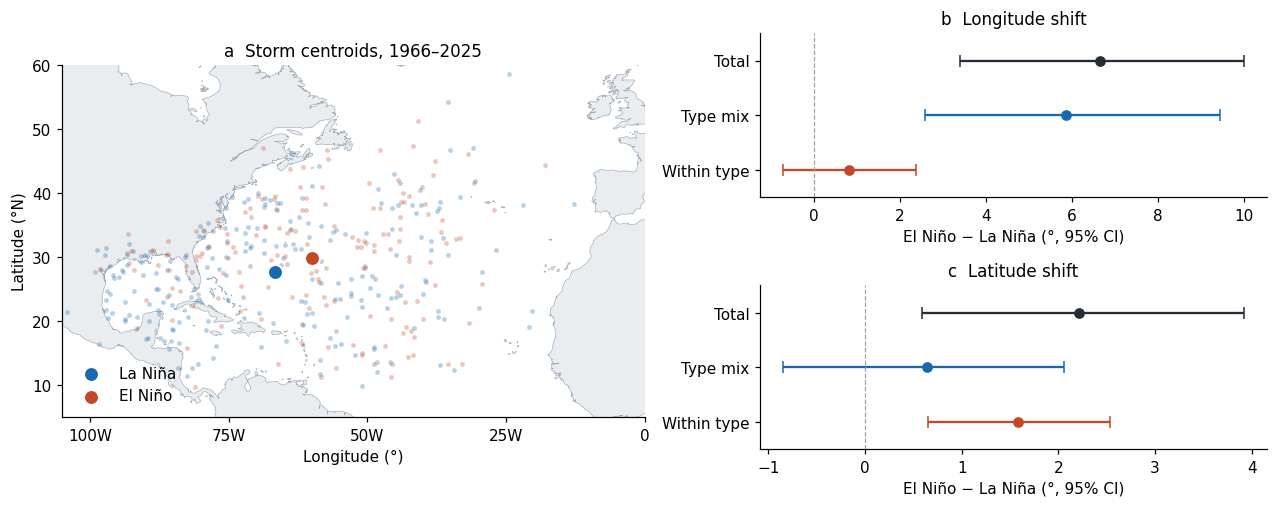

**Longitude:** total 6.66°; type mix 5.85°; within type 0.81°.

**Latitude:** total 2.22°; type mix 0.64°; within type 1.58°.

In [5]:
decomposition = aa.decompose(storms, storms.k)
aa.write_table(decomposition, 'centroid_decomposition')
display(decomposition.round(4))
aa.fig_decomposition(storms, decomposition)
for axis in ['longitude', 'latitude']:
    t = decomposition.query('axis == @axis').set_index('component')
    display(Markdown(f"**{axis.capitalize()}:** total {t.loc['total','estimate']:.2f}°; "
                     f"type mix {t.loc['type_mix','estimate']:.2f}°; "
                     f"within type {t.loc['within_type','estimate']:.2f}°."))

**Figure 4 | Exact decomposition of centroid displacement.** Map points represent 226 La Niña and 165 El Niño storms across 14 and 15 seasons; large points show storm-weighted means. Right panels show total, composition, and within-type contrasts with 95% intervals from 2,000 season bootstraps. The table reports six-component Holm adjustment of global-null permutation tests. Intervals are marginal and conditional on fixed labels.

The **eastward point estimate is dominated by composition**; the northward estimate has a larger within-type component. These compare estimated contributions, not whether one p value passes a threshold while another does not.

## 6. Robustness: geometry, grouping, time, and influential seasons

We examine five sensitivities:

1. **Geometry and K:** geodesic K=3–7 refits, with component estimates and 2,000 season-bootstrap intervals conditional on each fitted classification.
2. **Latitude trend:** remove a linear year trend fitted to all 1966–2025 storm centroids, retaining atlas labels. The trend is fixed during resampling; this is a plug-in sensitivity, not full environmental-confounding adjustment.
3. **Count scope:** repeat count contrasts from 1950, 1966, and 1980 for all storms, hurricanes (category ≥1), and major hurricanes (category ≥3). This tests counts, not the full decomposition in every window.
4. **Single-season influence:** omit each of 29 non-neutral seasons and recompute total centroid contrasts without additional hypothesis tests.
5. **Temporal alignment:** rotate all 60 years of ENSO labels, including neutral years, through every cyclic alignment against the unchanged storm record. Cyclic phase ordering and phase counts are retained. Activity and decomposition are recomputed at each alignment; the reference proportion includes the observed alignment, giving minimum p=1/60. Holm correction is separate for three activity and six decomposition statistics.

Circular shifts assume exchangeable relative alignment under a stationary null, including an artificial wraparound boundary. They probe serial dependence without removing long-term nonstationarity. Results supplement rather than replace independent-season inference.

,model,axis,component,estimate,ci_low,ci_high,p_permutation,p_holm
0,Atlas K = 4,longitude,total,6.6562,3.4034,9.9907,0.0005,0.0030
1,Atlas K = 4,longitude,type_mix,5.8493,2.5812,9.4431,0.0025,0.0112
2,Atlas K = 4,longitude,within_type,0.8069,-0.7095,2.3784,0.3470,0.6940
3,Atlas K = 4,latitude,total,2.2182,0.5905,3.9185,0.0145,0.0435
4,Atlas K = 4,latitude,type_mix,0.6378,-0.8435,2.0572,0.3792,0.6940
5,Atlas K = 4,latitude,within_type,1.5803,0.6549,2.5300,0.0022,0.0112
6,Geodesic K = 3,longitude,total,6.6562,3.2649,10.0014,0.0010,0.0060
7,Geodesic K = 3,longitude,type_mix,6.0617,2.7723,9.2281,0.0010,0.0060
8,Geodesic K = 3,longitude,within_type,0.5945,-0.9875,2.1773,0.4980,0.4980
9,Geodesic K = 3,latitude,total,2.2182,0.6311,4.0973,0.0110,0.0330


,start,min_category,delta_storms_per_year,ci_low,ci_high,p,n_nina_seasons,n_nino_seasons
0,1950,0,4.8278,2.3110,7.4279,0.0010,18,20
1,1950,1,2.9167,1.3722,4.4833,0.0025,18,20
2,1950,3,1.7278,0.8889,2.5168,0.0010,18,20
3,1966,0,5.1429,2.0235,8.8051,0.0082,14,15
4,1966,1,3.0048,1.1470,4.9381,0.0082,14,15
5,1966,3,1.6381,0.5857,2.6144,0.0070,14,15
6,1980,0,6.9167,2.9829,10.9842,0.0035,10,12
7,1980,1,4.1333,2.0833,6.0833,0.0012,10,12
8,1980,3,2.0000,0.8496,3.0167,0.0058,10,12


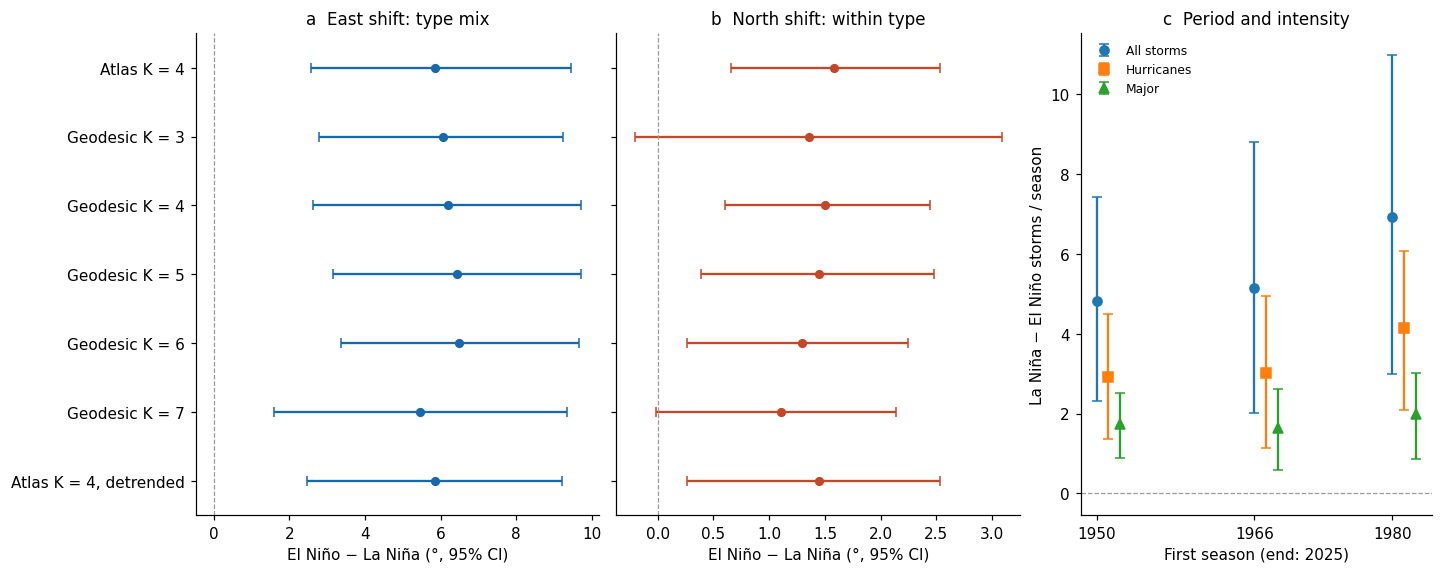

,min,max
axis,,
latitude,1.845,2.587
longitude,5.767,7.695


,outcome,estimate,p_circular,p_holm_within_family,alignments
0,storms,5.1429,0.0167,0.0500,60
1,ace,47.9022,0.0167,0.0500,60
2,us,2.0190,0.0333,0.0500,60
3,longitude_total,6.6562,0.0167,0.1000,60
4,longitude_type_mix,5.8493,0.0167,0.1000,60
5,longitude_within_type,0.8069,0.3333,0.6333,60
6,latitude_total,2.2182,0.0167,0.1000,60
7,latitude_type_mix,0.6378,0.3167,0.6333,60
8,latitude_within_type,1.5803,0.0333,0.1000,60


**Northward within-type estimates:** Atlas K = 4: 1.58° [95% CI 0.65, 2.53], within-model Holm p=0.011; Geodesic K = 3: 1.36° [95% CI -0.21, 3.09], within-model Holm p=0.210; Geodesic K = 4: 1.50° [95% CI 0.60, 2.45], within-model Holm p=0.016; Geodesic K = 5: 1.45° [95% CI 0.38, 2.48], within-model Holm p=0.040; Geodesic K = 6: 1.29° [95% CI 0.27, 2.25], within-model Holm p=0.044; Geodesic K = 7: 1.11° [95% CI -0.01, 2.14], within-model Holm p=0.117; Atlas K = 4, detrended: 1.45° [95% CI 0.26, 2.54], within-model Holm p=0.069.

In [6]:
robust, sensitivity, leave_one_out = aa.robustness(storms, fits, season)
display(robust[['model','axis','component','estimate','ci_low','ci_high','p_permutation','p_holm']].round(4))
display(sensitivity.round(4))
aa.fig_robustness(robust, sensitivity)
display(leave_one_out.groupby('axis').estimate.agg(['min','max']).round(3))
temporal = aa.temporal_sensitivity(storms, season)
display(temporal.round(4))
north = robust.query('axis == "latitude" and component == "within_type"')
display(Markdown('**Northward within-type estimates:** ' + '; '.join(
    f"{r.model}: {r.estimate:.2f}° [95% CI {r.ci_low:.2f}, {r.ci_high:.2f}], within-model Holm p={r.p_holm:.3f}"
    for r in north.itertuples()) + '.'))

**Figure 5 | Sensitivity of effect sizes and uncertainty.** Panels a–b compare atlas labels, geodesic K=3–7, and the detrended atlas analysis; rows correspond across panels. All use 391 non-neutral storms from 29 seasons. Bars are marginal 95% intervals from 2,000 season bootstraps with fitted types held fixed. Panel c shows count contrasts across windows and intensity thresholds, also with 2,000 season bootstraps. La Niña/El Niño sample sizes are 18/20 seasons from 1950, 14/15 from 1966, and 10/12 from 1980. Each model's six-component Holm results are tabulated; no across-model selection is used to declare a preferred model.

Eastward composition estimates remain positive across the displayed classifications. Northward within-type estimates are also positive, but their intervals include zero at geodesic K=3 and K=7. After detrending, the marginal interval is positive while six-component Holm p=0.069; the interval and adjusted test address different coverage/testing questions. **Direction is more stable than threshold-based declarations across settings.**

Circular-shift activity p values are 0.017–0.033 (Holm 0.050); those for total longitude, longitude type mix, total latitude, and latitude within type are 0.017–0.033 (Holm 0.100). These coarse temporal references indicate an unusual observed alignment but do not reproduce every rejection from independent-year permutations. Inferential strength depends on how temporal dependence is represented.

## 7. Track moments: location, spread, and distribution shape

For positions $(x_i,y_i)$, first moments are $\bar x,\bar y$; sample variances and covariance use denominator $n-1$. Skewness is $m_3/m_2^{3/2}$ and excess kurtosis is $m_4/m_2^2-3$, where $m_j=n^{-1}\sum_i(x_i-\bar x)^j$; latitude is analogous. Skewness and kurtosis use SciPy's `bias=True` convention.

These **nine moments describe spatial distributions of fixes**. A northward latitude tail does not establish when a track turned north. Tracks with fewer than four fixes or non-finite moments are excluded; all 391 primary non-neutral tracks are retained.

Contrasts are El Niño minus La Niña storm-weighted means, with year-label permutations and BH correction across nine tests. Gaussian KDE curves are descriptive, using Scott bandwidth. Reflection at zero for variances and −2 for excess kurtosis respects their support; this display correction changes neither input moments nor tests.

,moment,delta_nino_minus_nina,p_permutation,q_bh
0,Ex,6.65622,0.0002,0.00180
1,Ey,2.21817,0.0142,0.03802
2,Vx,28.29596,0.0945,0.12150
3,Vy,-0.00579,0.9996,0.99960
4,Cxy,13.58299,0.0689,0.10335
5,Sx,0.04886,0.4922,0.55372
6,Sy,-0.16261,0.0169,0.03802
7,Kx,0.22745,0.0547,0.09846
8,Ky,-0.19108,0.0060,0.02700


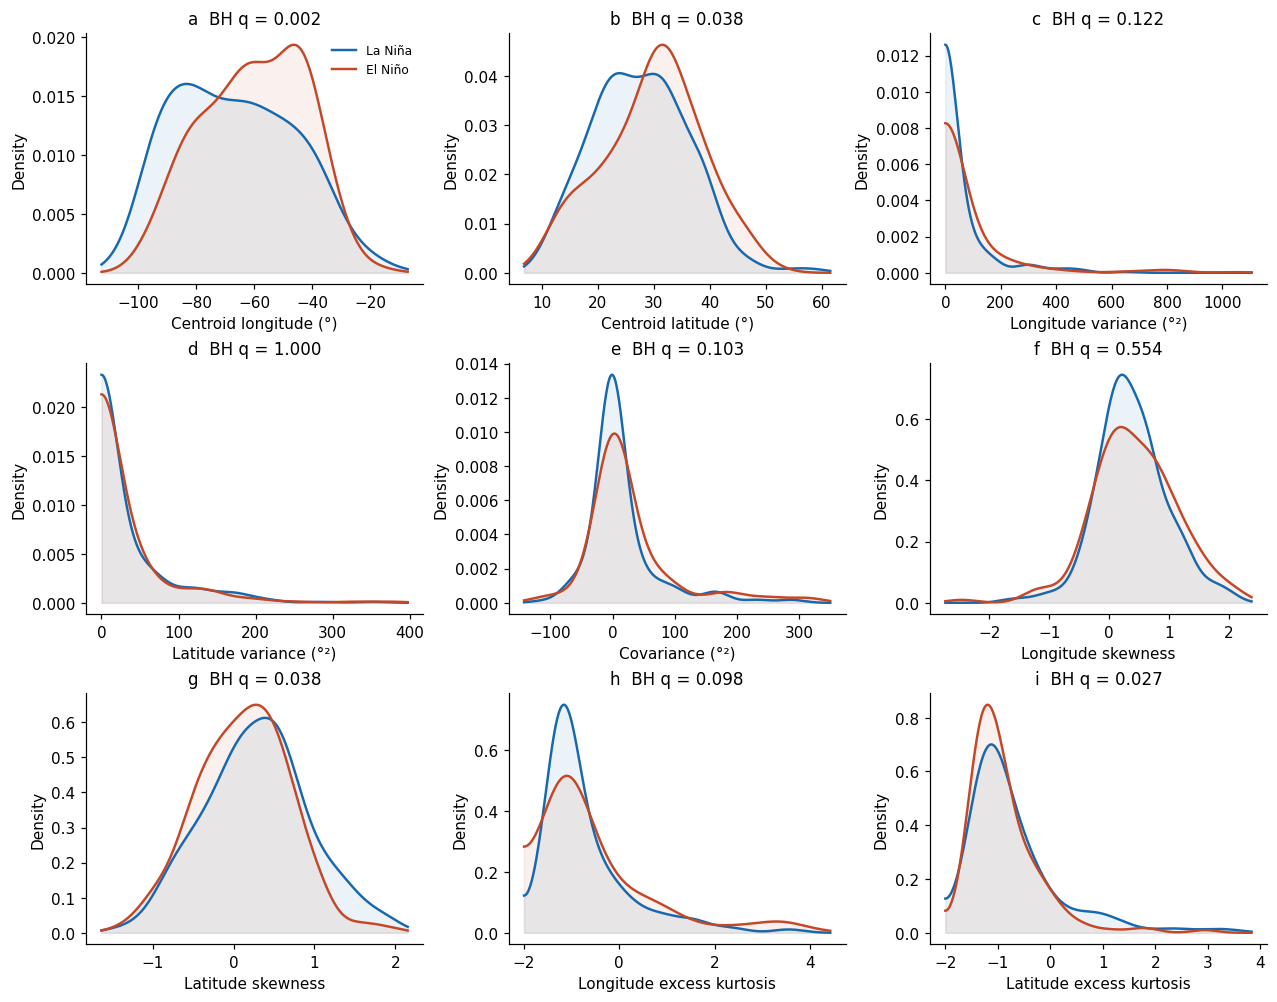

Moments with BH-adjusted q<0.05 under year exchangeability: **Ex, Ey, Sy, Ky**.

In [7]:
moment_table = aa.moment_results(storms)
display(moment_table.round(5))
aa.fig_moments(storms, moment_table)
selected = moment_table.loc[moment_table.q_bh < .05, 'moment'].tolist()
display(Markdown('Moments with BH-adjusted q<0.05 under year exchangeability: **' + ', '.join(selected) + '**.'))

**Figure 6 | Nine track-moment distributions.** Blue and orange show 226 La Niña and 165 El Niño storms from 14 and 15 seasons. KDE curves span observations plus a small extension, constrained and reflected at theoretical lower boundaries. Panel labels are BH-adjusted p values (denoted q) for nine mean contrasts under 9,999 season-label permutations. They test mean differences, not equality of entire distributions. Each moment retains its own units.

Group differences can coexist with extensive overlap. Individual discrimination requires testing storm records from held-out seasons.

## 8. Individual information and the higher-order increment

The response is season phase (La Niña=1, El Niño=0). Six feature sets use identical balanced logistic regression: centroid, first plus second moments, skewness plus kurtosis, all nine moments, first eligible position ("genesis"), and geodesically resampled positions. Models use L2 regularization, C=1, and at most 2,000 iterations. Standardization is fitted **within each training fold**; no hyperparameter search is performed.

Unique years are randomly assigned to ten folds. Storms of a year stay together. Pooled out-of-fold AUC is averaged across ten seeds (0–9). Class balancing addresses changing training-class proportions. Each of 199 year-label permutations repeats scaling and fitting on identical folds, giving an empirical null that includes pooling predictions from separate fits. Minimum attainable Monte Carlo p=0.005.

The incremental question is

$$\Delta AUC=AUC(\mathrm{all\ nine})-AUC(\mathrm{first+second}).$$

Both models use identical resampled seasons and folds. Each of 1,000 phase-stratified season bootstraps refits both models and repeats ten-fold averaging. Repeated copies of a sampled season retain the **same original year ID**, preventing duplicate storms crossing training and test folds. Saved results include each model's AUC and their paired difference. Fold assignments are numerical averaging, not independent replicates for uncertainty estimation.

This is retrospective discrimination from **completed tracks**, not early forecasting or validation on future periods. Randomization and bootstrap share the independent-season assumptions above; Section 6's temporal test concerns activity and geography rather than classifier validation.

Centroid: AUC 0.601; permutation p 0.005


First + second: AUC 0.603; permutation p 0.005


Skewness + kurtosis: AUC 0.568; permutation p 0.035


All nine moments: AUC 0.625; permutation p 0.005


Genesis: AUC 0.579; permutation p 0.010


...

Paired season bootstrap: 900/1000


Paired season bootstrap: 950/1000


Paired season bootstrap: 1000/1000


,features,auc,split_min,split_max,null_mean,null_05,null_95,p_permutation,q_bh
0,Centroid,0.6012,0.5918,0.6094,0.4827,0.3938,0.5457,0.005,0.0075
1,First + second,0.6025,0.5875,0.6126,0.4863,0.4200,0.5448,0.005,0.0075
2,Skewness + kurtosis,0.5676,0.5595,0.5839,0.4934,0.4108,0.5603,0.035,0.0350
3,All nine moments,0.6247,0.6072,0.6407,0.4907,0.4139,0.5599,0.005,0.0075
4,Genesis,0.5792,0.5682,0.5909,0.4814,0.4005,0.5529,0.010,0.0120
5,Resampled track,0.6087,0.5930,0.6244,0.4880,0.4199,0.5504,0.005,0.0075


,delta,ci_low,ci_high,bootstrap,permutations,splits,seasons,storms,all_nine_ci_low,all_nine_ci_high
0,0.0222,-0.0405,0.0795,1000,199,10,29,391,0.5079,0.6821


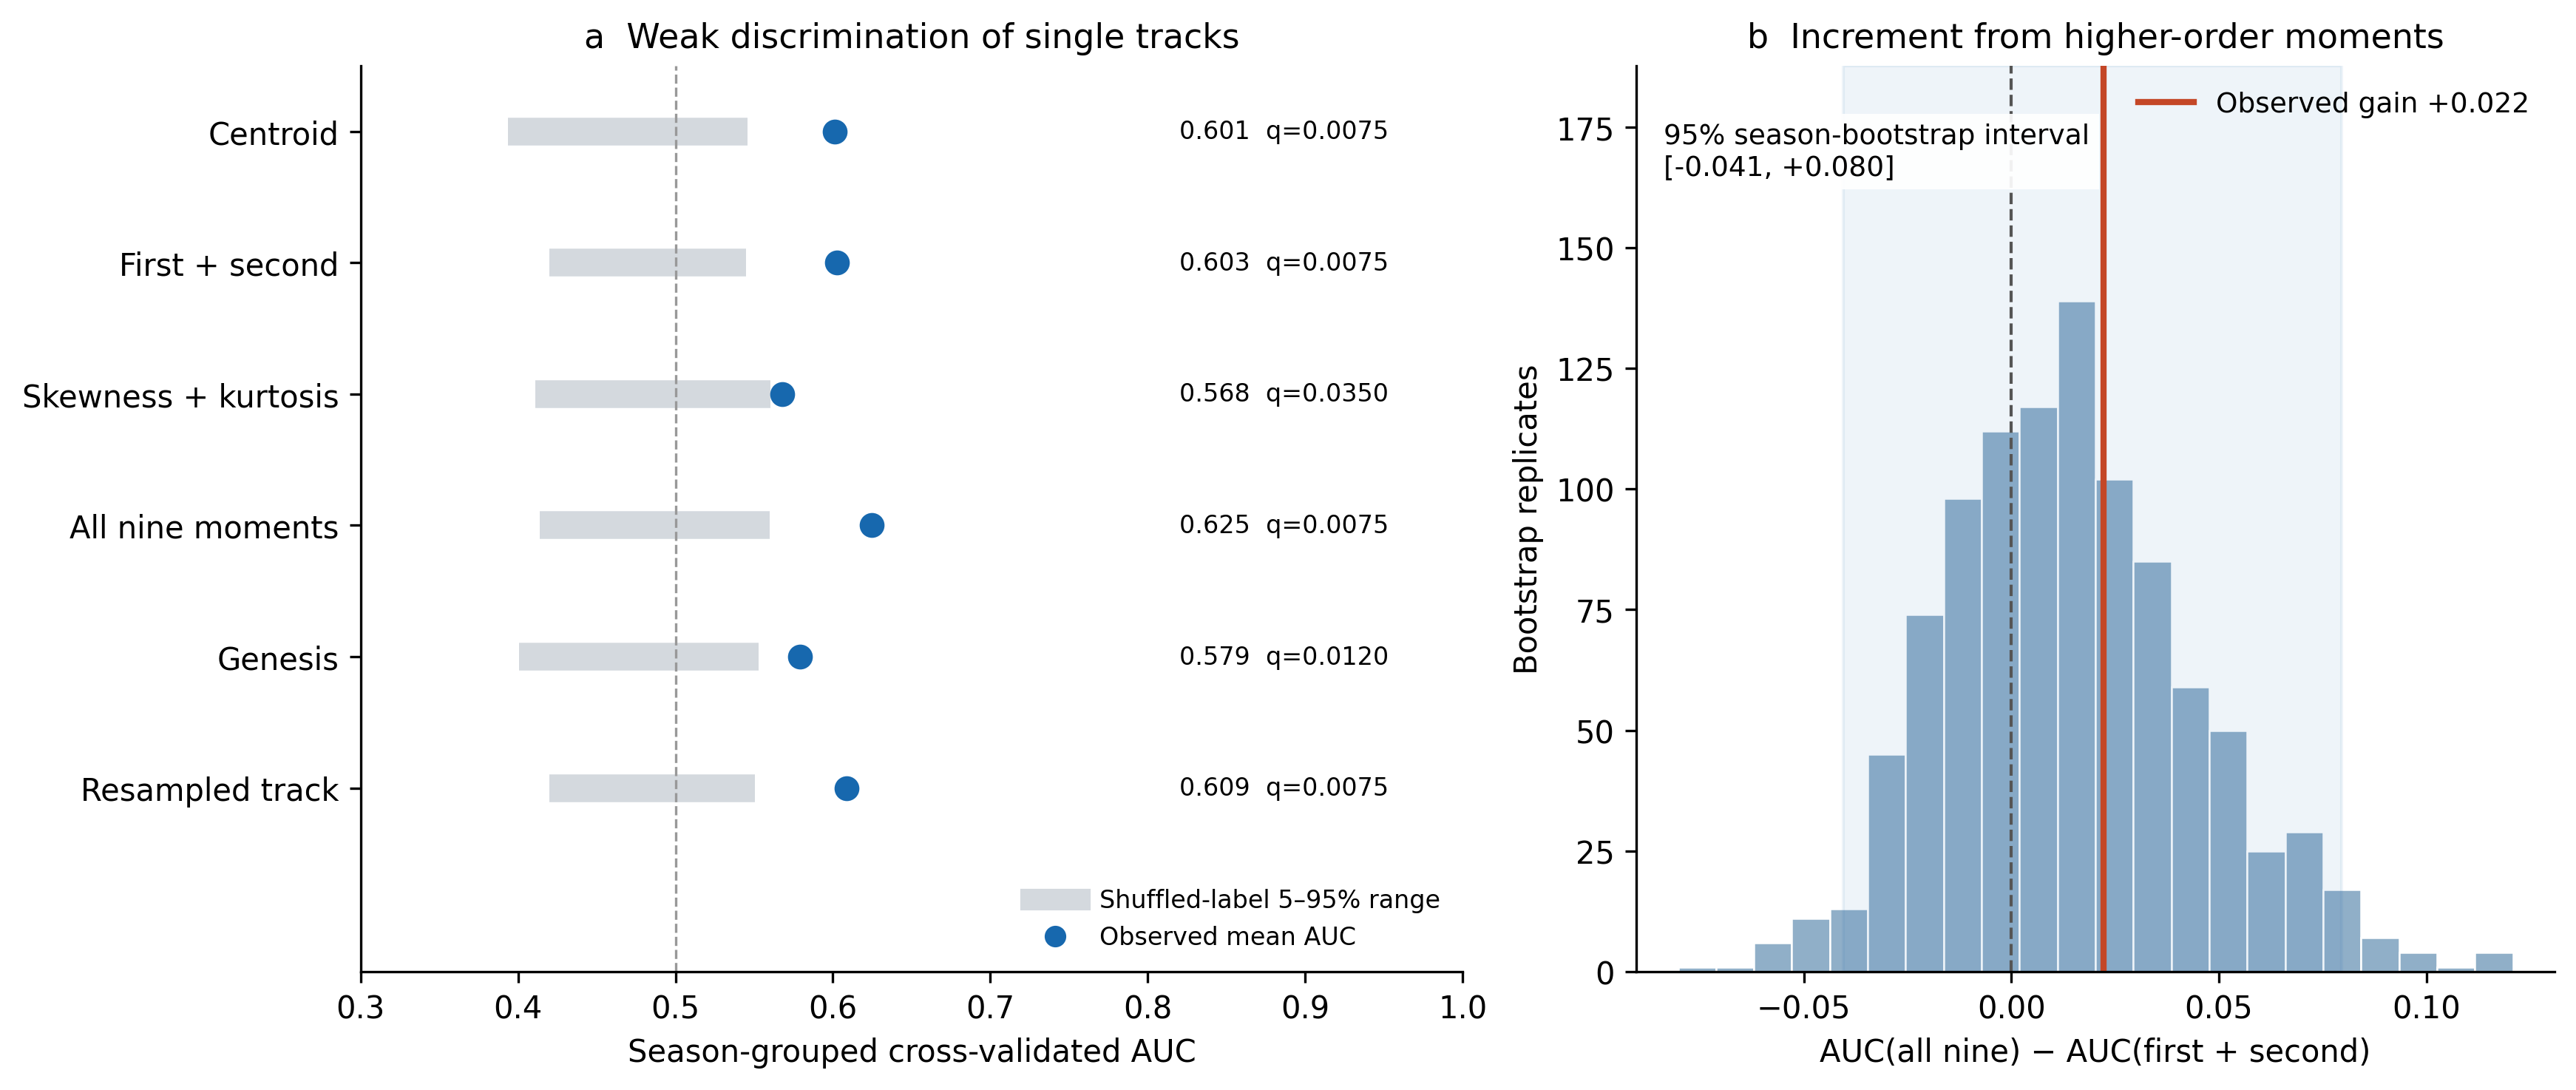

All nine moments yield **AUC=0.625** (season-bootstrap 95% interval [0.508, 0.682]). The shuffled-label 5–95% range is [0.414, 0.560], with BH q=0.0075. Relative to first plus second moments (AUC=0.603), the increment is **+0.022**, with paired season-bootstrap 95% interval **[-0.041, +0.080]**.

In [8]:
classification_table, gains, gain = aa.classification(storms, features,
                                                    splits=10, permutations=199, bootstrap=1000)
display(classification_table.round(4))
display(pd.DataFrame([gain]).round(4))
aa.fig_classification(classification_table, gains, gain)
all9 = classification_table.set_index('features').loc['All nine moments']
low = classification_table.set_index('features').loc['First + second']
display(Markdown(f"All nine moments yield **AUC={all9.auc:.3f}** "
                 f"(season-bootstrap 95% interval [{gain['all_nine_ci_low']:.3f}, {gain['all_nine_ci_high']:.3f}]). "
                 f"The shuffled-label 5–95% range is [{all9.null_05:.3f}, {all9.null_95:.3f}], "
                 f"with BH q={all9.q_bh:.4f}. Relative to first plus second moments (AUC={low.auc:.3f}), "
                 f"the increment is **{gain['delta']:+.3f}**, with paired season-bootstrap "
                 f"95% interval **[{gain['ci_low']:+.3f}, {gain['ci_high']:+.3f}]**."))

**Figure 7 | Individual discrimination and higher-order information.** Panel a: dots show mean AUC across ten year-grouped fold assignments for 391 storms in 29 seasons. Grey bars are 5–95% ranges from 199 year-label permutation refits, **not confidence intervals for observed AUC**. BH adjustment spans six feature sets. Panel b: 1,000 paired season-bootstrap AUC differences; the orange line marks the observed increment, shading its 95% interval, and a dashed line zero gain. Each bootstrap refits both models on identical grouped folds.

AUC near 0.63 indicates limited discrimination despite detectable phase-associated information under the primary null. A positive increment whose interval spans zero does not establish reliable extra information from skewness and kurtosis. It also does not establish an exactly zero contribution.

## 9. Discussion: a population shift, not one characteristic track

The evidence forms a connected sequence. La Niña seasons have greater average activity in the primary record. A substantial part of the count difference lies in the Gulf–Caribbean type. Because this type occupies the western basin, composition changes are reflected in an eastward population-centroid contrast. Within-type changes account for more of the northward point estimate, although their uncertainty is more sensitive to classification and inference choices.

These patterns are compatible with ENSO's known environmental pathways [1]. Wind shear, humidity, steering flow, and Atlantic sea-surface temperatures are not included as measured mediators. The decomposition explains **how the observed contrast is composed**, rather than identifying a physical causal mechanism.

The central reproducible pattern is a geographic redistribution of the storm population. Higher-order moments describe individual shapes more finely, but the available seasons do not establish incremental discrimination beyond position and spread. Seasonal interpretation should emphasize occurrence and location rather than a distinctive, accurately identifiable "El Niño track".

Scope is set by 29 non-neutral primary seasons, rounded processed coordinates, retained post-tropical positions, and the operational US-landfall indicator. Intervals condition on fitted types; K sensitivity does not capture all clustering uncertainty. Temporal sensitivity shows how inferential strength varies with the representation of year-to-year dependence. These qualifications locate the evidence without changing observed effect sizes.

### Conclusion and evidence map

The following table is populated from this execution and links estimates to figures and machine-readable results.

In [9]:
lon = decomposition.query('axis == "longitude"').set_index('component')
lat = decomposition.query('axis == "latitude"').set_index('component')
claims = pd.DataFrame([
    {'Conclusion': 'Seasonal activity differs between phases', 'Evidence': f"Count difference {activity.iloc[0].delta_nina_minus_nino:.2f}/season; primary Holm p={activity.iloc[0].p_holm:.4f}", 'Source': 'Figs. 1–2; seasonal_contrasts.csv'},
    {'Conclusion': 'Gulf–Caribbean tracks contribute much of the count contrast', 'Evidence': f"Type-rate difference {type_rates.iloc[0].delta_nina_minus_nino:.2f}/season; Holm p={type_rates.iloc[0].p_holm:.4f}", 'Source': 'Fig. 3; type_rates.csv'},
    {'Conclusion': 'Type mix dominates the eastward point estimate', 'Evidence': f"Total {lon.loc['total','estimate']:.2f}°; mix {lon.loc['type_mix','estimate']:.2f}°", 'Source': 'Figs. 4–5; centroid_decomposition.csv'},
    {'Conclusion': 'Northward within-type displacement is setting-sensitive', 'Evidence': f"Total {lat.loc['total','estimate']:.2f}°; within type {lat.loc['within_type','estimate']:.2f}°; inspect sensitivity intervals", 'Source': 'Figs. 4–5; decomposition_robustness.csv'},
    {'Conclusion': 'Temporal assumptions affect inferential strength', 'Evidence': 'Circular-shift Holm p=0.050 for activity; 0.100 for four main spatial statistics', 'Source': 'temporal_sensitivity.csv'},
    {'Conclusion': 'Single-track discrimination is limited', 'Evidence': f"All-nine AUC={all9.auc:.3f}; primary BH q={all9.q_bh:.4f}", 'Source': 'Figs. 6–7; classification.csv'},
    {'Conclusion': 'An incremental higher-order gain is not established', 'Evidence': f"Delta AUC={gain['delta']:+.3f}; 95% CI [{gain['ci_low']:+.3f}, {gain['ci_high']:+.3f}]", 'Source': 'Fig. 7; auc_gain_bootstrap.csv'}
])
display(claims)
aa.write_table(claims, 'claim_evidence')
display(Markdown(f"**Synthesis.** La Niña seasons in 1966–2025 average "
                 f"{activity.iloc[0].delta_nina_minus_nino:.2f} more storms than El Niño seasons. "
                 f"The El Niño population lies {lon.loc['total','estimate']:.2f}° farther east and "
                 f"{lat.loc['total','estimate']:.2f}° farther north. Type mix accounts for most of "
                 "the eastward point estimate; within-type displacement contributes to the northward contrast. "
                 f"Individual tracks remain weak discriminators (AUC={all9.auc:.3f}). "
                 "The coherent result is a change in which storms occur and where they travel, with "
                 "inferential strength that varies across temporal and classification assumptions."))
assert np.isclose(type_rates.delta_nina_minus_nino.sum(), activity.iloc[0].delta_nina_minus_nino)
for t in [lon, lat]:
    assert np.isclose(t.loc['total','estimate'], t.loc['type_mix','estimate']+t.loc['within_type','estimate'])
assert gain['seasons'] == 29 and gain['storms'] == 391 and gain['bootstrap'] == 1000
assert all(len(list(aa.FIG.glob(f'fig*.{suffix}'))) == 7 for suffix in ['png','pdf','svg'])
print('Consistency checks passed; all figures and results were generated in this execution.')

,Conclusion,Evidence,Source
0,Seasonal activity differs between phases,Count difference 5.14/season; primary Holm p=0...,Figs. 1–2; seasonal_contrasts.csv
1,Gulf–Caribbean tracks contribute much of the c...,Type-rate difference 3.60/season; Holm p=0.0008,Fig. 3; type_rates.csv
2,Type mix dominates the eastward point estimate,Total 6.66°; mix 5.85°,Figs. 4–5; centroid_decomposition.csv
3,Northward within-type displacement is setting-...,Total 2.22°; within type 1.58°; inspect sensit...,Figs. 4–5; decomposition_robustness.csv
4,Temporal assumptions affect inferential strength,Circular-shift Holm p=0.050 for activity; 0.10...,temporal_sensitivity.csv
5,Single-track discrimination is limited,All-nine AUC=0.625; primary BH q=0.0075,Figs. 6–7; classification.csv
6,An incremental higher-order gain is not establ...,"Delta AUC=+0.022; 95% CI [-0.041, +0.080]",Fig. 7; auc_gain_bootstrap.csv


**Synthesis.** La Niña seasons in 1966–2025 average 5.14 more storms than El Niño seasons. The El Niño population lies 6.66° farther east and 2.22° farther north. Type mix accounts for most of the eastward point estimate; within-type displacement contributes to the northward contrast. Individual tracks remain weak discriminators (AUC=0.625). The coherent result is a change in which storms occur and where they travel, with inferential strength that varies across temporal and classification assumptions.

Consistency checks passed; all figures and results were generated in this execution.


## 10. Reproduction and references

- **Implementation:** `atlas_analysis.py` contains statistics, plotting, seeds, grouping, and corrections.
- **Inputs:** `data/atlas_snapshot.json`, `data/atlantic_land.geojson`, and `data/manifest.json` contain fixed records, coastlines, and checksums. No network is required after dependency installation.
- **Results:** `results/*.csv` includes estimates, null references, bootstrap samples, geodesic cluster assignments, and the evidence map; `results/environment.json` records versions.
- **Figures:** `figures/fig01`–`fig07` provide 300 dpi PNG and PDF/SVG artwork, generated by the executed code.
- **Validation:** `scripts/run_research_notebook.py` executes from a fresh kernel; `scripts/check_research_notebook.py` independently checks results, formulas, grouping, and outputs.

The notebook shares the atlas's inputs and primary labels, adding geodesic resampling, uncertainty, multiplicity correction, and temporal sensitivity. Geodesic clusters and their predictive scores need not match the website's coordinate-space approximation. The primary moment classifier keeps the same features and observed averaging convention. Figures are analysis outputs, not website screenshots.

1. **NOAA CPC.** *ENSO FAQ.* [Atlantic hurricane environment](https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/ensofaq.shtml).
2. **Nakamura, J., Lall, U., Kushnir, Y. & Camargo, S. J. (2009).** Classifying North Atlantic Tropical Cyclone Tracks by Mass Moments. *Journal of Climate*, **22**, 5481–5494. [doi:10.1175/2009JCLI2828.1](https://doi.org/10.1175/2009JCLI2828.1).
3. **Knapp, K. R., Kruk, M. C., Levinson, D. H., Diamond, H. J. & Neumann, C. J. (2010).** The International Best Track Archive for Climate Stewardship (IBTrACS): Unifying Tropical Cyclone Data. *Bulletin of the American Meteorological Society*, **91**, 363–376. [doi:10.1175/2009BAMS2755.1](https://doi.org/10.1175/2009BAMS2755.1); [NOAA NCEI](https://www.ncei.noaa.gov/products/international-best-track-archive).
4. **NOAA CPC.** *ONI (ERSSTv5).* [Historical data](https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt). Outcomes end in 2025; the ongoing 2026 season is excluded.
5. **Natural Earth / world-atlas.** 1:50m land polygons. [Natural Earth](https://www.naturalearthdata.com/); [world-atlas v2.0.2](https://github.com/topojson/world-atlas/tree/v2.0.2).
6. **scikit-learn documentation.** [Haversine angular-distance formula](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.haversine_distances.html). Implemented directly for adjacent fixes.

Snapshot date: 2026-10-19. Version data revisions as new snapshots to distinguish input changes from analysis changes.